In [4]:
import numpy as np
import matplotlib.pyplot as plt
predata=np.loadtxt('data/train.csv', delimiter=',', skiprows=1)


In [5]:
np.save("data/train.npy", predata)

In [6]:
data=np.load("data/train.npy")

In [7]:
print(data.shape)

(42000, 785)


In [8]:
np.random.seed(0)

In [9]:
shuffle_list=np.random.permutation(len(data))
data=data[shuffle_list]

In [10]:
ntest=4200
test_data=data[:ntest]
train_data=data[ntest:]

In [11]:
test_data.shape

(4200, 785)

In [12]:
train_data.shape


(37800, 785)

In [13]:
x_train=train_data[:,1:]
y_train=train_data[:,0]
x_test=test_data[:,1:]
y_test=test_data[:,0]

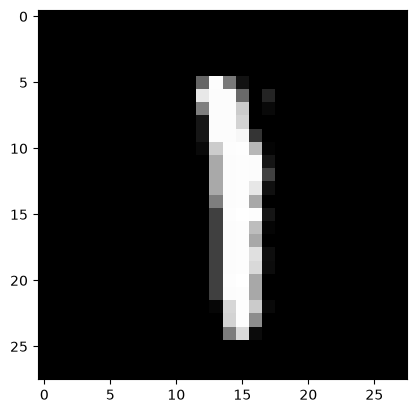

In [14]:
row=x_train[52].reshape(28,28)
plt.imshow(row, cmap='gray')


In [15]:
x_train=x_train/255.0
x_test=x_test/255.0
y_train=y_train.astype(int)
y_test=y_test.astype(int)

In [16]:
y_train_oh=np.eye(10)[y_train]
y_test_oh=np.eye(10)[y_test]

In [17]:
np.random.seed(0)
w1=np.random.randn(784, 128)*np.sqrt(2/784)
b1=np.zeros((1, 128))
w2=np.random.randn(128, 10)*np.sqrt(2/128)
b2=np.zeros((1, 10))

In [18]:
def forward(x):
    z1 = np.matmul(x, w1) + b1
    a1 = np.maximum(0, z1)
    z2 = np.matmul(a1, w2) + b2

    shifted = z2 - z2.max(axis=1, keepdims=True)
    e = np.exp(shifted)
    a2 = e / e.sum(axis=1, keepdims=True)

    return z1, a1, z2, a2

In [19]:
z1, a1, z2, a2 = forward(x_train)
compare=y_train==np.argmax(a2,axis=1)
compare.mean()

np.float64(0.11362433862433863)

In [20]:
def loss(a2, y):
    return -np.mean(np.sum(y * np.log(a2 + 1e-9), axis=1))

In [21]:
def backward(x, y, z1, a1, a2):
    dz2 = (a2 - y) / len(y)
    dw2 = np.matmul(a1.T, dz2)
    db2 = np.sum(dz2, axis=0, keepdims=True)

    da1 = np.matmul(dz2, w2.T)
    dz1 = da1 * (z1 > 0)
    dw1 = np.matmul(x.T, dz1)
    db1 = np.sum(dz1, axis=0, keepdims=True)

    return dw1, db1, dw2, db2

In [22]:
z1, a1, z2, a2=forward(x_train[:64])

In [23]:
dw1, db1, dw2, db2=backward(x_train[:64], y_train_oh[:64], z1, a1 , a2)
dw1.shape, db1.shape, dw2.shape, db2.shape  


((784, 128), (1, 128), (128, 10), (1, 10))

In [24]:
og=w2[3,4]
dw2[3,4]
eps=1e-5
w2[3,4]+=eps
z1, a1, z2, a2=forward(x_train[:64])
loss_plus=loss(a2, y_train_oh[:64])

In [25]:
w2[3,4]-=eps
z1, a1, z2, a2=forward(x_train[:64])
loss_minus=loss(a2, y_train_oh[:64])
w2[3,4]=og

In [26]:
numerical_grad = (loss_plus - loss_minus) / (2 * eps)
xs = x_train[:64]
Ys = y_train_oh[:64]

# analytic gradients, computed once before touching any weight
z1, a1, z2, a2 = forward(xs)
dw1, db1, dw2, db2 = backward(xs, Ys, z1, a1, a2)

def grad_check(param, analytic, idx, eps=1e-5):
    orig = param[idx]

    param[idx] = orig + eps
    loss_plus = loss(forward(xs)[3], Ys)

    param[idx] = orig - eps
    loss_minus = loss(forward(xs)[3], Ys)

    param[idx] = orig  # restore

    numerical = (loss_plus - loss_minus) / (2 * eps)
    a = analytic[idx]
    rel = abs(a - numerical) / (abs(a) + abs(numerical) + 1e-12)
    print(f"analytic={a:.8f}  numerical={numerical:.8f}  rel diff={rel:.2e}")

grad_check(w2, dw2, (3, 4))
grad_check(w1, dw1, (400, 10))
grad_check(b1, db1, (0, 5))
grad_check(b2, db2, (0, 3))


analytic=-0.02267098  numerical=-0.02267098  rel diff=7.00e-09
analytic=0.00128688  numerical=0.00128688  rel diff=1.61e-08
analytic=-0.00183340  numerical=-0.00183340  rel diff=5.49e-09
analytic=0.00364204  numerical=0.00364204  rel diff=7.57e-08
